# Pakistan Smog Forecast: Analysis and Backtest

**Author:** Anas Khan · Data Science student

Every winter, smog makes the air in Lahore and other Pakistani cities among the most polluted in the world. This notebook:

1. describes the seasonal pattern of PM2.5 in **Lahore, Peshawar, Islamabad and Karachi** (August 2022 – September 2026),
2. examines the **weather conditions** that trap pollution,
3. builds **1-, 2- and 3-day forecasts** and backtests them against simple baselines on a period the model never saw,
4. explains what the model relies on.

**Data caveat:** PM2.5 comes from the Copernicus (CAMS) global atmospheric model via Open-Meteo, not ground monitors. It tracks seasonal and day-to-day changes but underestimates the worst ground-level peaks, so the absolute numbers here are conservative.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import permutation_importance
from smog import model as M

ROOT = Path("..").resolve()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
CITY_COLORS = {"Lahore": "#E4572E", "Peshawar": "#4C7AF2", "Islamabad": "#29A36A", "Karachi": "#8E5BD9"}
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

daily = pd.read_csv(ROOT / "data" / "processed" / "daily.csv", parse_dates=["date"])
print(f"{len(daily):,} city-days · {daily['date'].min().date()} to {daily['date'].max().date()} · "
      f"{daily['pm25'].notna().mean():.1%} of days have PM2.5")

6,072 city-days · 2022-08-05 to 2026-09-30 · 99.9% of days have PM2.5


## 1. The smog season

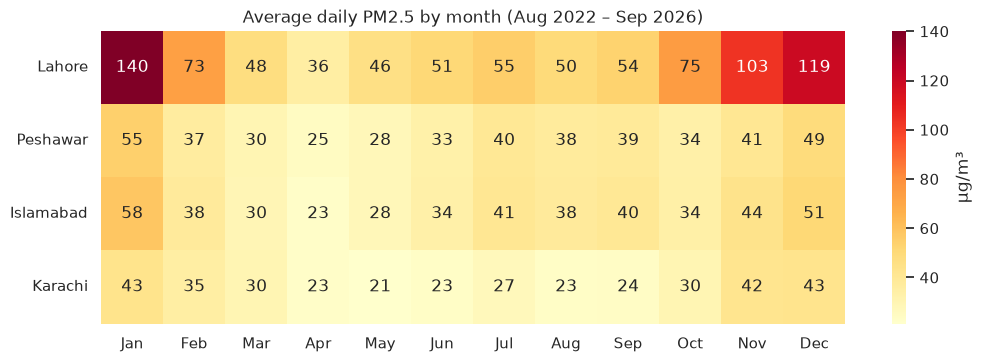

In [2]:
monthly = daily.assign(month=daily["date"].dt.month).groupby(["city", "month"])["pm25"].mean().unstack()
monthly = monthly.loc[["Lahore", "Peshawar", "Islamabad", "Karachi"]]
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(monthly, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "µg/m³"}, ax=ax,
            xticklabels=["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set(title="Average daily PM2.5 by month (Aug 2022 – Sep 2026)", xlabel="", ylabel="")
save(fig, "01_monthly_heatmap")
plt.show()

In [3]:
cats = daily.dropna(subset=["pm25"]).assign(category=lambda d: M.aqi_category(d["pm25"].to_numpy()).to_numpy())
share = pd.crosstab(cats["city"], cats["category"], normalize="index").reindex(columns=M.AQI_LABELS, fill_value=0) * 100
share.loc[["Lahore", "Peshawar", "Islamabad", "Karachi"]].round(1)

category,Good,Moderate,Unhealthy for sensitive groups,Unhealthy,Very unhealthy,Hazardous
city,,,,,,
Lahore,0.0,15.9,32.2,41.0,10.5,0.5
Peshawar,0.2,50.5,38.8,10.6,0.0,0.0
Islamabad,0.0,48.0,38.9,13.2,0.0,0.0
Karachi,0.1,75.7,17.2,7.0,0.0,0.0


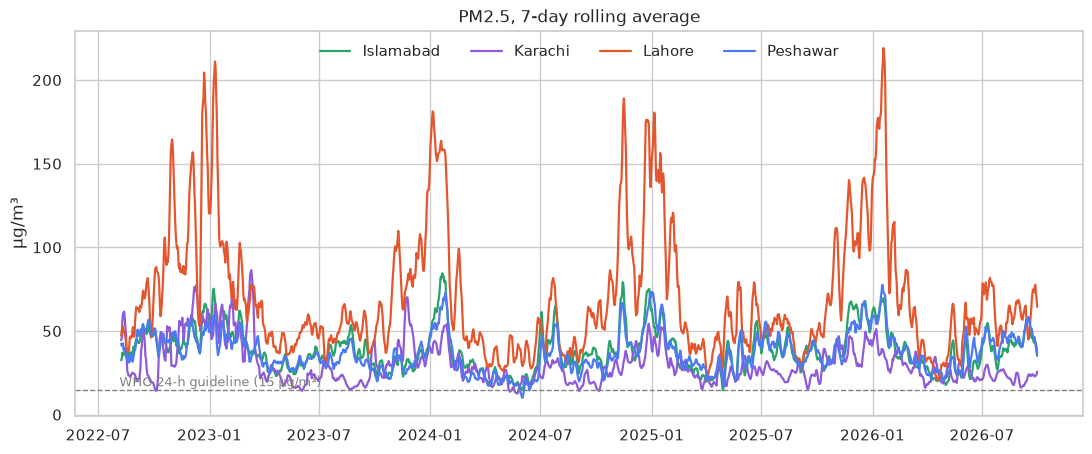

In [4]:
fig, ax = plt.subplots(figsize=(13, 5))
for city, g in daily.groupby("city"):
    ax.plot(g["date"], g["pm25"].rolling(7, min_periods=4).mean(), color=CITY_COLORS[city], lw=1.6, label=city)
ax.axhline(15, color="grey", ls="--", lw=1); ax.text(daily["date"].min(), 17, "WHO 24-h guideline (15 µg/m³)", color="grey", fontsize=9)
ax.set(title="PM2.5, 7-day rolling average", ylabel="µg/m³", xlabel="")
ax.legend(frameon=False, ncol=4)
save(fig, "02_timeseries")
plt.show()

- **Lahore stands apart.** Its average PM2.5 is **140 µg/m³ in January**, 117 in December and 103 in November, against about 36 in April, and it never drops to "Good". On **52% of all days** Lahore's air is *Unhealthy* or worse by US EPA categories, and in November–January **41% of days reach "Very unhealthy" or "Hazardous"** levels (above 125.4 µg/m³).
- Peshawar and Islamabad follow a milder version of the same winter pattern (about 55–58 µg/m³ in January), while **Karachi is cleanest** (three-quarters of days "Moderate"), helped by sea breezes.
- Every winter repeats the same build-up. Lahore's worst 7-day average reached 211 µg/m³ in winter 2022–23 and **219 µg/m³ in winter 2025–26**.
- Even Karachi's cleanest months stay above the WHO 24-hour guideline of 15 µg/m³ on most days.

These are CAMS model estimates, which are known to underestimate ground-level extremes in South Asia, so the real picture, especially in Peshawar, is likely worse.

## 2. What traps the smog? Weather drivers

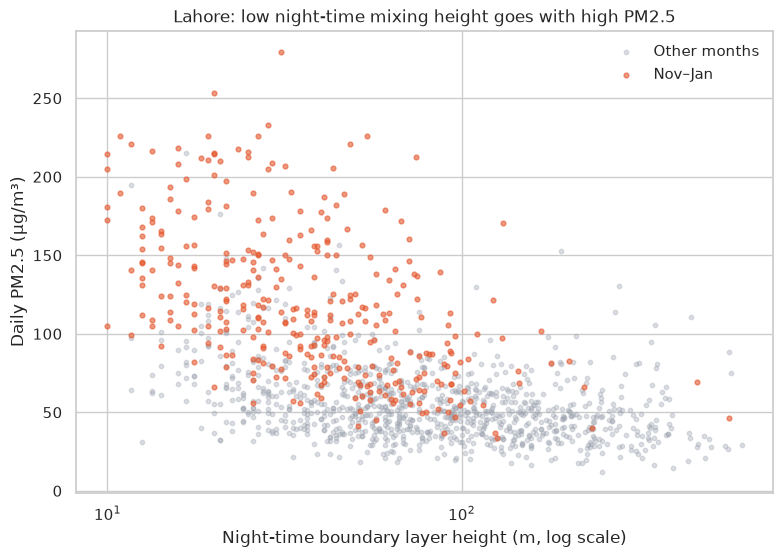

,Lahore,Peshawar,Islamabad,Karachi
blh_night,-0.54,-0.15,-0.10,-0.58
blh_mean,-0.53,-0.28,-0.29,-0.42
wind_mean,-0.49,-0.27,-0.34,-0.47
temp_mean,-0.47,-0.23,-0.22,-0.40
rh_mean,0.33,0.35,0.27,-0.43
temp_range,0.05,-0.23,-0.22,0.51
precip_sum,-0.28,-0.01,-0.02,-0.29


In [5]:
lahore = daily[daily["city"] == "Lahore"].dropna(subset=["pm25", "blh_night"])
winter = lahore["date"].dt.month.isin([11, 12, 1])
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(lahore.loc[~winter, "blh_night"], lahore.loc[~winter, "pm25"], s=10, alpha=.35, color="#9CA3AF", label="Other months")
ax.scatter(lahore.loc[winter, "blh_night"], lahore.loc[winter, "pm25"], s=12, alpha=.6, color="#E4572E", label="Nov–Jan")
ax.set(xscale="log", title="Lahore: low night-time mixing height goes with high PM2.5",
       xlabel="Night-time boundary layer height (m, log scale)", ylabel="Daily PM2.5 (µg/m³)")
ax.legend(frameon=False)
save(fig, "03_blh_vs_pm25")
plt.show()

weather = ["blh_night", "blh_mean", "wind_mean", "temp_mean", "rh_mean", "temp_range", "precip_sum"]
corr = pd.DataFrame({city: g[weather + ["pm25"]].corr(method="spearman")["pm25"].drop("pm25")
                     for city, g in daily.groupby("city")})
corr[["Lahore", "Peshawar", "Islamabad", "Karachi"]].round(2)

- In **Lahore**, PM2.5 rises sharply when the **night-time mixing height** is low (Spearman ρ = −0.54) and when **wind** is weak (ρ = −0.49). On calm winter nights the boundary layer can collapse to just tens of metres, trapping smoke from vehicles, industry, brick kilns and crop burning near the ground: a temperature inversion.
- Cold days are dirtier (ρ = −0.47 with temperature), mostly because cold days are calm, stable winter days rather than because of temperature itself.
- **Karachi** behaves differently: there, *humid* days are cleaner (ρ = −0.43) because humidity arrives with the sea breeze that ventilates the city, while in the three northern cities humidity goes with *more* pollution (fog and haze).
- In this model data, Peshawar's and Islamabad's PM2.5 depends less on local mixing (ρ ≈ −0.10 to −0.15). One plausible reason is that CAMS represents their pollution as more regionally transported; ground sensors might show a stronger local signal. That is a hypothesis, not something this data can confirm.

## 3. Forecasting: backtest

**Setup.** For each issue day *t*, predict the daily mean PM2.5 on day *t+1*, *t+2* and *t+3* from recent PM2.5 (today, 1, 2 and 6 days ago, and the 7-day mean), today's weather, the **target day's weather**, the season, and the city. One gradient-boosting model per horizon, trained on log(PM2.5).

**Honest split.** Train on everything whose *target* falls before **1 August 2025**; test on every forecast issued from 1 August 2025 to September 2026. That covers the full 2025–26 smog winter and is strictly later than the training data.

**Baselines.** *Persistence* (the future equals today, which is hard to beat at short range) and *seasonal average* (the training-period mean for that city and time of year).

In [6]:
scores = pd.read_csv(ROOT / "data" / "processed" / "backtest_scores.csv")
pred = pd.read_csv(ROOT / "data" / "processed" / "backtest_predictions.csv", parse_dates=["date", "target_date"])
table = scores.pivot_table(index="method", columns="horizon", values="MAE").loc[
    ["Persistence", "Climatology", "Ridge regression", "Gradient boosting"]]
table.index = ["Persistence", "Seasonal average", "Ridge regression", "Gradient boosting"]
print("Mean absolute error (µg/m³), test period Aug 2025 – Sep 2026")
table.round(2)

Mean absolute error (µg/m³), test period Aug 2025 – Sep 2026


horizon,1,2,3
Persistence,7.59,10.38,11.59
Seasonal average,10.73,10.74,10.74
Ridge regression,8.76,9.50,9.88
Gradient boosting,6.45,8.01,8.70


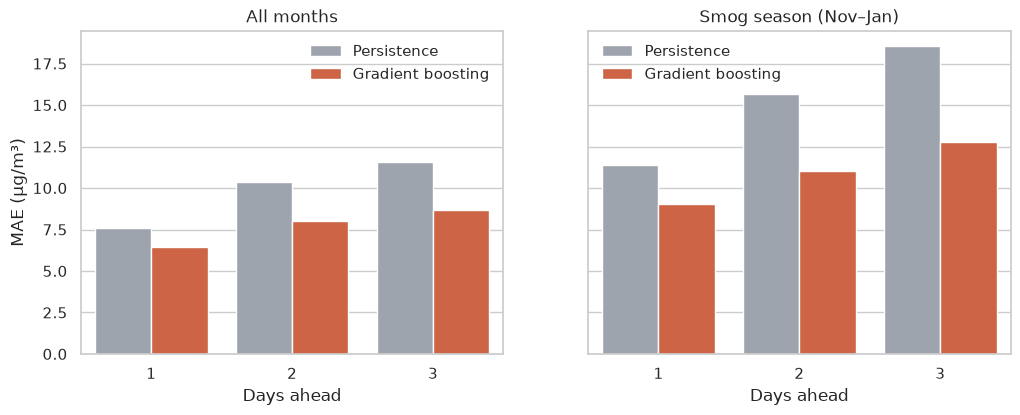

method                         Gradient boosting  Persistence  improvement
period                horizon                                             
All months            1                      6.4          7.6         15.1
                      2                      8.0         10.4         22.9
                      3                      8.7         11.6         24.9
Smog season (Nov–Jan) 1                      9.0         11.4         20.8
                      2                     11.0         15.7         29.8
                      3                     12.8         18.6         31.1

In [7]:
rows = []
for h, g in pred.groupby("horizon"):
    for label, mask in {"All months": slice(None), "Smog season (Nov–Jan)": g["target_date"].dt.month.isin([11, 12, 1])}.items():
        s = g.loc[mask]
        for method in ["Persistence", "Gradient boosting"]:
            rows.append({"horizon": h, "period": label, "method": method, "MAE": (s[method] - s["target"]).abs().mean()})
mae = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, (period, g) in zip(axes, mae.groupby("period")):
    sns.barplot(data=g, x="horizon", y="MAE", hue="method", palette=["#9CA3AF", "#E4572E"], ax=ax)
    ax.set(title=period, xlabel="Days ahead", ylabel="MAE (µg/m³)"); ax.legend(frameon=False)
save(fig, "04_mae_by_horizon")
plt.show()
mae.pivot_table(index=["period", "horizon"], columns="method", values="MAE").assign(
    improvement=lambda t: (1 - t["Gradient boosting"] / t["Persistence"]) * 100).round(1)

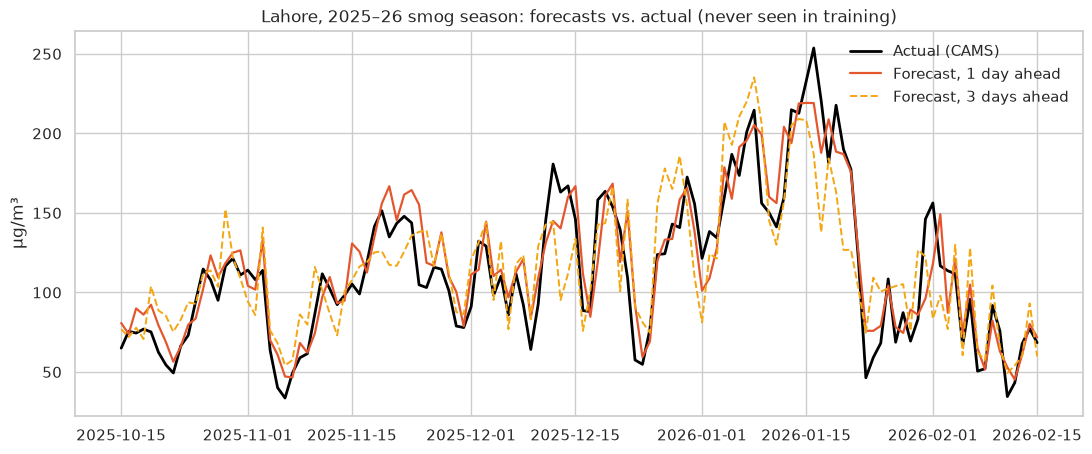

In [8]:
season = pred[(pred["city"] == "Lahore") & pred["target_date"].between("2025-10-15", "2026-02-15")]
fig, ax = plt.subplots(figsize=(13, 5))
one = season[season["horizon"] == 1].sort_values("target_date")
three = season[season["horizon"] == 3].sort_values("target_date")
ax.plot(one["target_date"], one["target"], color="black", lw=2, label="Actual (CAMS)")
ax.plot(one["target_date"], one["Gradient boosting"], color="#E4572E", lw=1.6, label="Forecast, 1 day ahead")
ax.plot(three["target_date"], three["Gradient boosting"], color="#F3A712", lw=1.4, ls="--", label="Forecast, 3 days ahead")
ax.set(title="Lahore, 2025–26 smog season: forecasts vs. actual (never seen in training)", ylabel="µg/m³", xlabel="")
ax.legend(frameon=False)
save(fig, "05_lahore_winter")
plt.show()

- The gradient-boosting model **beats both baselines at every horizon** on a test period it never saw (August 2025 – September 2026): MAE **6.4, 8.0 and 8.7 µg/m³** at 1, 2 and 3 days, which is **15%, 23% and 25% better than persistence**.
- The gain is largest when it matters most. In the **smog season (November–January)** the improvement grows to **21–31%**; at 3 days ahead the error falls from 18.6 (persistence) to 12.8 µg/m³.
- Persistence is a strong baseline at 1 day because pollution changes slowly. The model's advantage grows with the horizon, because it knows the coming weather (calm, low-mixing days ahead) while persistence does not.
- The seasonal average is weak (MAE ≈ 10.7) because it cannot follow day-to-day swings, and Ridge regression is worse than gradient boosting because the weather effects are non-linear (for example, mixing height only matters once it gets very low).
- On the Lahore 2025–26 chart, the 1-day forecast tracks the build-ups and clean-outs closely, and the 3-day forecast catches most of the big episodes but smooths and sometimes mistimes the sharpest peaks.
- **Important caveat:** in the backtest, the target day's weather comes from observed weather data (ERA5), i.e. a *perfect* weather forecast. Live forecasts use real weather forecasts, so real-world errors will be somewhat larger, especially at 3 days.

## 4. What does the model rely on?

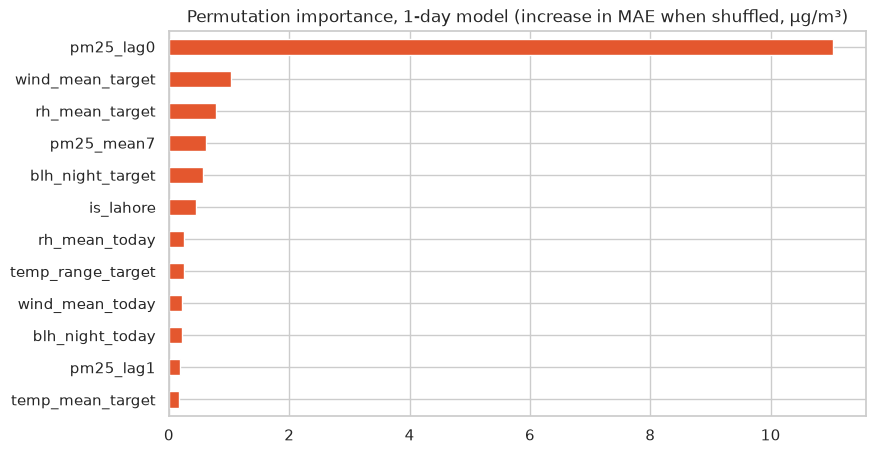

pm25_lag0            11.04
wind_mean_target      1.02
rh_mean_target        0.78
pm25_mean7            0.62
blh_night_target      0.56
is_lahore             0.45
rh_mean_today         0.24
temp_range_target     0.24
wind_mean_today       0.22
blh_night_today       0.21
pm25_lag1             0.18
temp_mean_target      0.17
dtype: float64

In [9]:
split = pd.Timestamp("2025-08-01")
frame = M.make_features(daily, 1).dropna(subset=["target", "pm25_lag0"])
cols = M.feature_columns(frame)
train = frame[frame["target_date"] < split].dropna(subset=cols)
test = frame[frame["date"] >= split].dropna(subset=cols)
gb = M.LogTarget(M.models()["Gradient boosting"]).fit(train[cols], train["target"])

imp = permutation_importance(gb, test[cols], test["target"], scoring="neg_mean_absolute_error",
                             n_repeats=10, random_state=42, n_jobs=-1)
importance = pd.Series(imp.importances_mean, index=cols).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9, 5))
importance[::-1].plot.barh(ax=ax, color="#E4572E")
ax.set(title="Permutation importance, 1-day model (increase in MAE when shuffled, µg/m³)", xlabel="")
save(fig, "06_importance")
plt.show()
importance.round(2)

- **Today's PM2.5** is by far the most important input (shuffling it raises the error by about 11 µg/m³): pollution builds up and clears over several days.
- Among weather variables, the **target day's wind** (+1.0), **humidity** (+0.8) and **night-time mixing height** (+0.6) matter most. The model uses the *forecast* conditions of the day being predicted, not just today's, which is why it beats persistence at longer horizons.
- The 7-day average PM2.5 adds context about whether the city is in an episode, and the Lahore indicator captures its much higher baseline.
- Permutation importance measures each input's unique contribution; correlated weather variables share credit, so individual numbers should not be over-interpreted.

## 5. Conclusions and limitations

**Findings**
1. Lahore's winter smog is severe and systematic: in November–January, 41% of days are "Very unhealthy" or worse even in conservative model data.
2. Calm air and a collapsed night-time boundary layer are the main weather conditions that trap the smog.
3. A gradient-boosting model using recent pollution and the weather forecast beats persistence by 15–25%, rising to 21–31% in smog season, at forecasting 1–3 days ahead.
4. The forecast is published automatically every morning by a GitHub Action, so the project keeps working without manual effort.

**Limitations**
- PM2.5 comes from the CAMS model, not ground monitors; it underestimates extremes, so levels are conservative.
- The backtest assumes perfect weather forecasts; live accuracy will be lower.
- City-wide daily averages hide hotspots and hourly peaks.
- One test period (one smog winter): results could differ in an unusual year.
- Emissions (crop burning, traffic, industry) are not modelled directly, only through their past effect on PM2.5.

**Next steps:** validate against ground monitors (for example the US consulate monitors or Punjab EPA stations), add satellite fire counts from crop burning as a feature, and forecast hourly peaks.